In [1]:
import os, sys, platform
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # hide TensorFlow's C++ info logs (set before importing TensorFlow)
ON_LINUXONE = platform.machine() == "s390x"
DATA_PATH = ("/home/ibm-user/transactions_history.csv" if ON_LINUXONE
             else "transactions_history.csv")
SEED = 42
TRAIN_END_YEAR = 2015         # train: up to 2015
VALID_YEARS = (2016, 2017)    # validation: compare models here
TEST_YEARS = (2018, 2019)     # test: used once, in the final test-evaluation cell

import pandas as pd
import numpy as np
import sklearn
import xgboost
import tensorflow as tf
import keras

print("Machine:", platform.machine(), "| Python:", sys.version.split()[0])

Machine: s390x | Python: 3.12.15


In [2]:
# 1. Load data
df = pd.read_csv(DATA_PATH)

# 2. Clean Amount: "$134.09" -> 134.09
df['Amount_num'] = df['Amount'].astype(str).str.replace('$', '', regex=False).astype(float)

# 3. Clean 'Is Fraud?' -> 1 / 0
# Bypass the object dtype check to support Pandas 3.x StringDtype
df['is_fraud'] = (df['Is Fraud?'].astype(str).str.strip().str.lower() == 'yes').astype(int)

# 4. Create single timestamp 'ts'
time_split = df['Time'].astype(str).str.split(':', expand=True)
df['hour'] = time_split[0].astype(int)
df['minute'] = time_split[1].astype(int)

df['ts'] = pd.to_datetime(dict(
    year=df['Year'],
    month=df['Month'],
    day=df['Day'],
    hour=df['hour'],
    minute=df['minute']
))

# 5. Sort chronologically
df = df.sort_values(by=['User', 'Card', 'ts']).reset_index(drop=True)

# 6. Assign train / valid / test splits by year
def assign_split(year):
    if year <= TRAIN_END_YEAR:
        return 'train'
    elif year in VALID_YEARS:
        return 'valid'
    elif year in TEST_YEARS:
        return 'test'
    else:
        return 'drop'

df['split'] = df['Year'].apply(assign_split)

# 7. Drop 2020+
df = df[df['split'] != 'drop'].reset_index(drop=True)

# 8. Print fraud counts to verify
fraud_counts = df.groupby('split')['is_fraud'].sum()
print("--- Fraud Count per Split ---")
print(fraud_counts)

--- Fraud Count per Split ---
split
test      60
train    178
valid     33
Name: is_fraud, dtype: int64


In [3]:
from sklearn.metrics import precision_score, recall_score, average_precision_score, confusion_matrix
import numpy as np

def threshold_for_budget(scores, alerts_per_1000=5):
    return float(np.quantile(np.asarray(scores), 1 - alerts_per_1000 / 1000.0))

def report(y_true, scores, threshold=None, alerts_per_1000=5):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    if threshold is None:
        threshold = threshold_for_budget(scores, alerts_per_1000)
    preds = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()

    res = {
        "threshold": threshold,
        "precision": precision_score(y_true, preds, zero_division=0),
        "recall": recall_score(y_true, preds, zero_division=0),
        "pr_auc": average_precision_score(y_true, scores),
        "fpr": fp / (fp + tn) if (fp + tn) > 0 else 0.0,
        "alerts_per_1000": ((tp + fp) / len(y_true)) * 1000
    }
    label = f"alert budget {alerts_per_1000} per 1,000" if alerts_per_1000 and threshold == threshold_for_budget(scores, alerts_per_1000) else "fixed threshold"
    print(f"--- Evaluation at {label} ---")
    for k, v in res.items():
        print(f"  {k:16s}: {v:.6f}")
    return res

In [4]:
# 1. Base numerical and time features
df['amount'] = df['Amount_num']
df['weekday'] = df['ts'].dt.dayofweek
df['is_refund'] = (df['amount'] < 0).astype(int)

# 2. Chip / Swipe / Online (One-hot encode)
chip_dummies = pd.get_dummies(df['Use Chip'], prefix='tx_type', dtype=int)
df = pd.concat([df, chip_dummies], axis=1)

# 3. Foreign merchant: a merchant state that is not a US state (online purchases have no state and are not foreign)
US_STATES = set(
    "AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO "
    "MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC".split()
)
state = df['Merchant State']
df['foreign_merchant'] = (state.notna() & ~state.isin(US_STATES)).astype(int)

# 4. Errors (One-hot encode comma-separated error types)
df['Errors?'] = df['Errors?'].fillna('')
errors_dummies = df['Errors?'].str.get_dummies(sep=',').add_prefix('err_')
df = pd.concat([df, errors_dummies], axis=1)

# 5. Define the final feature list
FEATURE_COLUMNS = ['amount', 'hour', 'weekday', 'is_refund', 'foreign_merchant', 'MCC'] + \
                  list(chip_dummies.columns) + list(errors_dummies.columns)

print("--- Feature Columns ---")
for col in FEATURE_COLUMNS:
    print(col)

print("\nFeature table shape:", df[FEATURE_COLUMNS].shape)

--- Feature Columns ---
amount
hour
weekday
is_refund
foreign_merchant
MCC
tx_type_Chip Transaction
tx_type_Online Transaction
tx_type_Swipe Transaction
err_Bad CVV
err_Bad Card Number
err_Bad Expiration
err_Bad PIN
err_Bad Zipcode
err_Insufficient Balance
err_Technical Glitch

Feature table shape: (242493, 16)


In [5]:
# === CELL: HISTORY FEATURES + LEAKAGE CHECK ===
def add_history_features(d):
    """Per-card history features that only look backwards.
    d must contain User, Card, ts, amount, Merchant Name, Merchant City."""
    d = d.sort_values(by=['User', 'Card', 'ts', 'amount']).reset_index(drop=True)
    g = d.set_index('ts').groupby(['User', 'Card'])

    # 1. Velocity (subtract the current transaction from counts and sums)
    d['count_1h'] = g['amount'].transform(lambda x: x.rolling('1h').count()).reset_index(drop=True) - 1
    d['count_24h'] = g['amount'].transform(lambda x: x.rolling('24h').count()).reset_index(drop=True) - 1
    d['count_7d'] = g['amount'].transform(lambda x: x.rolling('7D').count()).reset_index(drop=True) - 1
    d['amt_24h'] = g['amount'].transform(lambda x: x.rolling('24h').sum()).reset_index(drop=True) - d['amount']

    # 2. Minutes since previous transaction (first transaction of a card = 1 year)
    d['mins_since_last'] = d.groupby(['User', 'Card'])['ts'].diff().dt.total_seconds() / 60.0
    d['is_first_tx'] = d.groupby(['User', 'Card']).cumcount().eq(0).astype(int)
    d['mins_since_last'] = d['mins_since_last'].fillna(365 * 24 * 60)

    # 3. Behavior (median of the card's PREVIOUS amounts only)
    d['median_so_far'] = d.groupby(['User', 'Card'])['amount'].transform(
        lambda x: x.shift().expanding().median()).fillna(0)
    d['ratio_median'] = np.where(d['median_so_far'] > 0, d['amount'] / d['median_so_far'], 0)

    d['first_time_merchant'] = (~d.duplicated(subset=['User', 'Card', 'Merchant Name'])).astype(int)
    d['first_time_city'] = (~d.duplicated(subset=['User', 'Card', 'Merchant City'])).astype(int)
    return d


df = add_history_features(df)

NEW_FEATURES = ['count_1h', 'count_24h', 'count_7d', 'amt_24h', 'mins_since_last',
                'ratio_median', 'first_time_merchant', 'first_time_city']
FEATURE_COLUMNS.extend([f for f in NEW_FEATURES if f not in FEATURE_COLUMNS])

# Real leakage test: features computed with data only up to 2010 must equal the full-data values
print("--- Leakage check: recompute features on data cut at 2010-01-01 ---")
HIST = ['count_1h', 'count_24h', 'count_7d', 'amt_24h', 'mins_since_last',
        'median_so_far', 'first_time_merchant', 'first_time_city']
cut = add_history_features(
    df.loc[df['ts'] < '2010-01-01', ['User', 'Card', 'ts', 'amount', 'Merchant Name', 'Merchant City']].copy())
full = df[df['ts'] < '2010-01-01'].reset_index(drop=True)
for c in HIST:
    diff = (cut[c].astype(float) - full[c].astype(float)).abs().max()
    print(f"  {c:20s} max diff {diff}")
    assert diff == 0, f"future information leaks into {c}"
print("Leakage check PASSED: features computed with data up to 2010 are identical to the full-data values")
del cut, full

--- Leakage check: recompute features on data cut at 2010-01-01 ---
  count_1h             max diff 0.0
  count_24h            max diff 0.0
  count_7d             max diff 0.0
  amt_24h              max diff 0.0
  mins_since_last      max diff 0.0
  median_so_far        max diff 0.0
  first_time_merchant  max diff 0.0
  first_time_city      max diff 0.0
Leakage check PASSED: features computed with data up to 2010 are identical to the full-data values


In [6]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

for c in ['amount', 'amt_24h', 'ratio_median', 'mins_since_last']:
    df[c + '_log'] = signed_log(df[c])

top_mccs = df.loc[df['split'] == 'train', 'MCC'].value_counts().index[:30]
mcc_oh = pd.get_dummies(df['MCC'].where(df['MCC'].isin(top_mccs), -1), prefix='mcc', dtype=int)
df = pd.concat([df, mcc_oh], axis=1)

NN_FEATURES = [c for c in FEATURE_COLUMNS if c not in ('MCC', 'amount', 'amt_24h', 'ratio_median', 'mins_since_last')] + \
              ['amount_log', 'amt_24h_log', 'ratio_median_log', 'mins_since_last_log'] + \
              list(mcc_oh.columns)

In [7]:
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow.keras as keras
import tensorflow as tf

keras.utils.set_random_seed(SEED)

# 1. Isolate training and validation sets using NN_FEATURES
train_df = df[df['split'] == 'train'].copy()
valid_df = df[df['split'] == 'valid'].copy()

X_train = train_df[NN_FEATURES].copy()
y_train = train_df['is_fraud']
X_valid = valid_df[NN_FEATURES].copy()
y_valid = valid_df['is_fraud']

# Calculate class weights
num_non_fraud = (y_train == 0).sum()
num_fraud = (y_train == 1).sum()
total = num_non_fraud + num_fraud
class_weight = {0: (1 / num_non_fraud) * (total / 2.0), 1: (1 / num_fraud) * (total / 2.0)}

# 2. Scale and clip features [-10, 10]
scaler = StandardScaler()
X_train_scaled = np.clip(scaler.fit_transform(X_train), -10, 10)
X_valid_scaled = np.clip(scaler.transform(X_valid), -10, 10)

# 3. Build Model using Input layer
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[keras.metrics.AUC(curve='PR', name='pr_auc')]
)

# 4. IBM Z workaround: on LinuxONE, compiled predict()/evaluate() graphs keep the weights from their first
#    trace, so validation during fit() would never see the updated weights. Rebuild them every epoch.
class FreshValidationGraph(keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.model.test_function = None

def predict_fresh(m, X, batch_size=4096):
    m.make_predict_function(force=True)
    return m.predict(X, batch_size=batch_size, verbose=0).ravel()

early_stopping = EarlyStopping(monitor='val_pr_auc', patience=5, mode='max', restore_best_weights=True)

print("\nTraining TensorFlow model...")
model.fit(
    X_train_scaled, y_train,
    epochs=30,
    batch_size=2048,
    validation_data=(X_valid_scaled, y_valid),
    class_weight=class_weight,
    callbacks=[FreshValidationGraph(), early_stopping],
    verbose=1
)

valid_scores_tf = predict_fresh(model, X_valid_scaled)
print("\n--- TensorFlow Validation Results ---")
tf_metrics = report(y_valid, valid_scores_tf, alerts_per_1000=5)


Training TensorFlow model...
Epoch 1/30


 1/86 ━━━━━━━━━━━━━━━━━━━━ 1:38 1s/step - loss: 1.2665 - pr_auc: 8.8257e-04

16/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8390 - pr_auc: 0.0010     

34/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7545 - pr_auc: 0.0011

53/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7130 - pr_auc: 0.0015

...

52/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1002 - pr_auc: 0.1656

68/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0994 - pr_auc: 0.1614

85/86 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0983 - pr_auc: 0.1608

86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0928 - pr_auc: 0.1620 - val_loss: 0.0617 - val_pr_auc: 0.0613



--- TensorFlow Validation Results ---
--- Evaluation at alert budget 5 per 1,000 ---
  threshold       : 0.948242
  precision       : 0.063218
  recall          : 0.333333
  pr_auc          : 0.082159
  fpr             : 0.004848
  alerts_per_1000 : 5.170262


In [8]:
from tensorflow.keras.layers import LSTM, Masking

SEQ_LEN = 10

def create_sequences_all(scaled, seq_len=SEQ_LEN):
    X = np.zeros((len(df), seq_len, scaled.shape[1]), dtype='float32')
    rows = np.arange(len(df))
    pos = df.groupby(['User', 'Card']).cumcount().values
    for lag in range(seq_len):
        ok = pos >= lag
        if ok.any():
            X[ok, seq_len - 1 - lag] = scaled[rows[ok] - lag]
    return X

print("Building global sequences for LSTM...")
scaled_nn_all = np.clip(scaler.transform(df[NN_FEATURES]), -10, 10)
X_all_seq = create_sequences_all(scaled_nn_all)

train_mask = (df['split'] == 'train').values
valid_mask = (df['split'] == 'valid').values

X_train_seq = X_all_seq[train_mask]
y_train_seq = df.loc[train_mask, 'is_fraud'].values
X_valid_seq = X_all_seq[valid_mask]
y_valid_seq = df.loc[valid_mask, 'is_fraud'].values

# Build LSTM Model
lstm_model = Sequential([
    Input(shape=(SEQ_LEN, len(NN_FEATURES))),
    Masking(mask_value=0.),
    LSTM(32, activation='tanh', return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[keras.metrics.AUC(curve='PR', name='pr_auc')]
)

print("\nTraining LSTM model...")
lstm_model.fit(
    X_train_seq, y_train_seq,
    epochs=15,
    batch_size=1024,
    validation_data=(X_valid_seq, y_valid_seq),
    class_weight=class_weight,
    callbacks=[FreshValidationGraph(), EarlyStopping(monitor='val_pr_auc', patience=4, mode='max', restore_best_weights=True)],
    verbose=1
)

valid_scores_lstm = predict_fresh(lstm_model, X_valid_seq)
print("\n--- LSTM Sequence Validation Results ---")
lstm_metrics = report(y_valid_seq, valid_scores_lstm, alerts_per_1000=5)

Building global sequences for LSTM...



Training LSTM model...


Epoch 1/15


  1/172 ━━━━━━━━━━━━━━━━━━━━ 6:29 2s/step - loss: 0.9862 - pr_auc: 0.0020

  5/172 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.8145 - pr_auc: 0.0016

...

161/172 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0345 - pr_auc: 0.5683

166/172 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0344 - pr_auc: 0.5681

171/172 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0344 - pr_auc: 0.5680

172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0329 - pr_auc: 0.5675 - val_loss: 0.0223 - val_pr_auc: 0.0134



--- LSTM Sequence Validation Results ---
--- Evaluation at alert budget 5 per 1,000 ---
  threshold       : 0.870117
  precision       : 0.022989
  recall          : 0.121212
  pr_auc          : 0.025735
  fpr             : 0.005056
  alerts_per_1000 : 5.170262


In [9]:
# === CELL: XGBOOST MODEL ===
import xgboost as xgb

train_df = df[df['split'] == 'train'].copy()
valid_df = df[df['split'] == 'valid'].copy()
X_train = train_df[FEATURE_COLUMNS]
y_train = train_df['is_fraud']
X_valid = valid_df[FEATURE_COLUMNS]
y_valid = valid_df['is_fraud']

scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(scale_pos_weight=scale_weight, random_state=SEED)

print("Training XGBoost model...")
xgb_model.fit(X_train, y_train)
valid_scores_xgb = xgb_model.predict_proba(X_valid)[:, 1]

print("--- XGBoost Validation Results ---")
xgb_metrics = report(y_valid, valid_scores_xgb)  # standard 5-per-1,000 alert budget

Training XGBoost model...


--- XGBoost Validation Results ---
--- Evaluation at alert budget 5 per 1,000 ---
  threshold       : 0.007412
  precision       : 0.076923
  recall          : 0.393939
  pr_auc          : 0.335891
  fpr             : 0.004640
  alerts_per_1000 : 5.021691


In [10]:
from sklearn.metrics import average_precision_score

# 1. Gather predictions using predict_fresh
xgb_probs = xgb_model.predict_proba(X_valid)[:, 1]
tf_probs = predict_fresh(model, X_valid_scaled)
lstm_probs = predict_fresh(lstm_model, X_valid_seq)

# 2. Grid search best ensemble weights on validation via Average Precision
best_w = max(
    ((w1, w2, round(1 - w1 - w2, 2)) 
     for w1 in np.arange(0, 1.0001, 0.05) 
     for w2 in np.arange(0, 1.0001 - w1, 0.05)),
    key=lambda w: average_precision_score(y_valid, w[0]*xgb_probs + w[1]*lstm_probs + w[2]*tf_probs)
)
print("Best weights (XGB, LSTM, TF):", best_w)

ensemble_df = valid_df[['User', 'Card', 'ts', 'Amount_num']].copy()

# Individual model scores, used by the reason codes
ensemble_df['XGB_Score'] = xgb_probs
ensemble_df['TF_Score'] = tf_probs
ensemble_df['LSTM_Score'] = lstm_probs

blend = best_w[0]*xgb_probs + best_w[1]*lstm_probs + best_w[2]*tf_probs
ensemble_df['Blended_Risk'] = blend

# 3. Budget-driven Tiered Routing (Top 1 per 1,000 for RED, Top 5 per 1,000 for YELLOW)
red_thr = threshold_for_budget(blend, alerts_per_1000=1)
yellow_thr = threshold_for_budget(blend, alerts_per_1000=5)

ensemble_df['Action_Tier'] = np.select(
    [blend >= red_thr, blend >= yellow_thr],
    ['RED', 'YELLOW'],
    default='CLEAR'
)
ensemble_df['is_fraud'] = valid_df['is_fraud'].values

print("\n--- 🛡️ Validation Routing Summary by Alert Budget ---")
print(ensemble_df.groupby('Action_Tier')['is_fraud'].agg(transactions='size', frauds='sum'))
print("AP blend:", average_precision_score(y_valid, blend), "| AP XGBoost alone:", average_precision_score(y_valid, xgb_probs))

Best weights (XGB, LSTM, TF): (np.float64(0.7000000000000001), np.float64(0.25), np.float64(0.05))

--- 🛡️ Validation Routing Summary by Alert Budget ---
             transactions  frauds
Action_Tier                      
CLEAR               33485      19
RED                    34      13
YELLOW                135       1
AP blend: 0.36424275861078687 | AP XGBoost alone: 0.33589064126184487


In [11]:
# === CELL: REASON CODES (value-specific) ===
import xgboost as xgb
import numpy as np

# Alert thresholds of the two neural models at the same 5-per-1,000 budget (computed on validation)
tf_thr = threshold_for_budget(tf_probs, alerts_per_1000=5)
lstm_thr = threshold_for_budget(lstm_probs, alerts_per_1000=5)

# Fraud rate per merchant category in the TRAINING data, used to explain MCC honestly
mcc_fraud_rate = train_df.groupby('MCC')['is_fraud'].mean()
base_fraud_rate = train_df['is_fraud'].mean()
MCC_NAMES = {5311: "department store", 5300: "wholesale club", 5310: "discount store",
             4829: "money transfer", 5912: "drug store", 5411: "grocery store",
             5651: "family clothing", 5719: "home furnishing", 5499: "food store",
             5812: "restaurant", 5541: "gas station", 3504: "hotel"}

def describe_reason(feat, r):
    """One positively contributing feature -> one sentence built from this transaction's real values.
    Returns None when an honest sentence isn't possible, so the next feature is used instead."""
    v = r[feat] if feat in r.index else None
    if feat in ('amount', 'ratio_median'):
        if r['ratio_median'] >= 1.5:
            return f"Amount ${r['amount']:.2f} is {r['ratio_median']:.1f}x this card's usual amount"
        if 0 < r['ratio_median'] <= 0.3:
            return f"Unusually small amount (${r['amount']:.2f}, {r['ratio_median']:.1f}x usual), typical of card testing"
        return None
    if feat == 'count_1h' and v >= 2:
        return f"{int(v)} other transactions on this card in the last hour"
    if feat == 'count_24h' and v >= 3:
        return f"{int(v)} other transactions on this card in the last 24 hours"
    if feat == 'count_7d' and v >= 10:
        return f"{int(v)} other transactions on this card in the last 7 days"
    if feat == 'amt_24h' and v > 0:
        return f"${v:.2f} already spent on this card in the last 24 hours"
    if feat == 'mins_since_last' and v < 60:
        return f"Only {v:.0f} minutes since this card's previous transaction"
    if feat == 'foreign_merchant' and v == 1:
        return f"Merchant in {r['Merchant State']}, outside the US"
    if feat == 'first_time_city' and v == 1:
        city = str(r['Merchant City']).strip()
        return "First purchase at a new location" if city.upper() == 'ONLINE' else f"First purchase ever in {city}"
    if feat == 'first_time_merchant' and v == 1:
        return "First purchase ever at this merchant"
    if feat == 'tx_type_Online Transaction' and v == 1:
        return "Online purchase without the physical card"
    if feat == 'is_refund' and v == 1:
        return f"Refund of ${abs(r['amount']):.2f}"
    if feat == 'MCC':
        rate = mcc_fraud_rate.get(v, np.nan)
        if np.isnan(rate) or rate <= base_fraud_rate:
            return None
        name = MCC_NAMES.get(int(v), "merchant category")
        return f"{name.capitalize()} (MCC {int(v)}): {rate * 100:.2f}% of past purchases were fraud vs {base_fraud_rate * 100:.2f}% overall"
    if feat.startswith('err_') and v == 1:
        return f"Error on this attempt: {feat[4:]}"
    return None


def generate_reasons(pos_idx, row, valid_row, max_reasons=3):
    contribs = xgb_contribs[pos_idx][:-1]
    reasons = []
    for j in np.argsort(contribs)[::-1]:
        if contribs[j] <= 0 or len(reasons) >= max_reasons:
            break
        text = describe_reason(FEATURE_COLUMNS[j], valid_row)
        if text and text not in reasons:
            reasons.append(text)
    if len(reasons) < max_reasons and (row['LSTM_Score'] >= lstm_thr or row['TF_Score'] >= tf_thr):
        reasons.append("Recent sequence of transactions on this card is unlike its history (neural models)")
    return reasons or ["Several weak signals combined; no single dominant factor"]


xgb_contribs = xgb_model.get_booster().predict(xgb.DMatrix(X_valid), pred_contribs=True)

reasons_list = []
for pos_idx in range(len(ensemble_df)):
    row = ensemble_df.iloc[pos_idx]
    if row['Action_Tier'] != 'CLEAR':
        reasons_list.append(generate_reasons(pos_idx, row, valid_df.iloc[pos_idx]))
    else:
        reasons_list.append([])

ensemble_df['Reasons'] = reasons_list
active_triple_alerts = ensemble_df[ensemble_df['Action_Tier'] != 'CLEAR'].sort_values(by='Blended_Risk', ascending=False)

print("--- Automated Reason Codes (top 5 alerts) ---")
for _, row in active_triple_alerts.head(5).iterrows():
    print(f"\n[{row['Action_Tier']}] {row['ts']} | Amount: ${row['Amount_num']:.2f} | "
          f"risk {row['Blended_Risk']:.3f} | actual fraud: {'yes' if row['is_fraud'] else 'no'}")
    for i, reason in enumerate(row['Reasons'], 1):
        print(f"  {i}. {reason}")

--- Automated Reason Codes (top 5 alerts) ---

[RED] 2016-06-26 12:27:00 | Amount: $150.13 | risk 0.959 | actual fraud: yes
  1. Online purchase without the physical card
  2. Wholesale club (MCC 5300): 0.17% of past purchases were fraud vs 0.10% overall
  3. Amount $150.13 is 4.3x this card's usual amount

[RED] 2016-04-05 15:16:00 | Amount: $-471.00 | risk 0.956 | actual fraud: yes
  1. Online purchase without the physical card
  2. Only 9 minutes since this card's previous transaction
  3. $479.98 already spent on this card in the last 24 hours

[RED] 2016-07-24 10:41:00 | Amount: $267.66 | risk 0.948 | actual fraud: yes
  1. Amount $267.66 is 14.6x this card's usual amount
  2. Online purchase without the physical card
  3. Only 6 minutes since this card's previous transaction

[RED] 2016-07-24 14:47:00 | Amount: $57.87 | risk 0.934 | actual fraud: yes
  1. Online purchase without the physical card
  2. $418.16 already spent on this card in the last 24 hours
  3. Amount $57.87 is 3

In [12]:
# === CELL: GRANITE ANALYST NOTE (RED alerts only) ===
import re
import time
from llama_cpp import Llama

print("Loading IBM Granite LLM into memory...")
llm = Llama(
    model_path="/home/ibm-user/granite-4.0-h-350m-base-be.f16.gguf",
    n_ctx=1024,       # 512 is too small: the prompt alone uses most of it and notes get cut off
    n_threads=3,      # use all 3 cores of the LinuxONE VM
    verbose=False
)

# Examples teach the style. They use the same kind of reasons our system produces (incl. a refund),
# so the model has no unusual details to copy into other notes.
FEW_SHOT = """Rewrite the alert as one sentence for a bank fraud analyst. Use only the facts given.

Alert: RED | Amount: $412.50
Reasons:
- Online purchase without the physical card
- Amount $412.50 is 5.2x this card's usual amount
- 3 other transactions on this card in the last hour
Sentence: RED alert on a $412.50 online purchase, about 5.2 times this card's usual amount, after 3 other transactions on this card in the last hour.

Alert: RED | Amount: refund of $120.00
Reasons:
- Online purchase without the physical card
- Only 4 minutes since this card's previous transaction
- $250.00 already spent on this card in the last 24 hours
Sentence: RED alert on a refund of $120.00 made online, only 4 minutes after this card's previous transaction, with $250.00 already spent on this card in the last 24 hours.

"""

def amount_text(amount):
    return f"refund of ${abs(amount):.2f}" if amount < 0 else f"${amount:.2f}"

def granite_note(tier, amount, reasons, max_tokens=80):
    """Return one COMPLETE sentence, or None if the model could not finish one.
    A note is complete only if the model stopped by itself (finish_reason 'stop') and it ends with . ! or ?"""
    prompt = FEW_SHOT + f"Alert: {tier} | Amount: {amount_text(amount)}\nReasons:\n" + \
             "\n".join(f"- {r}" for r in reasons) + "\nSentence:"
    room = llm.n_ctx() - len(llm.tokenize(prompt.encode("utf-8"))) - 8   # tokens left in the context window
    budget = min(max_tokens, room)
    for _ in range(2):                       # second try only if the first one ran out of tokens
        if budget <= 0:
            return None
        out = llm(prompt, max_tokens=budget, stop=["\n", "Alert:"], temperature=0.0, echo=False)
        choice = out['choices'][0]
        text = choice['text'].strip()
        if choice['finish_reason'] == 'stop':
            return text if text.endswith(('.', '!', '?')) else None
        budget = min(budget * 2, room)       # cut off by the token limit: retry with more room
    return None

# Words that state a fact. If the note uses one, the facts we gave the model must contain it too.
# This catches details copied from the examples above (e.g. "Mexico", "3 other transactions").
FACT_WORDS = ['pin', 'cvv', 'zip', 'expiration', 'balance', 'glitch', 'card number', 'rome', 'italy', 'mexico',
              'city', 'merchant', 'refund', 'online', 'minute', 'hour', 'outside', 'never', 'new location']

def template_note(tier, amount, reasons):
    """Plain sentence built directly from the facts. Used when Granite's sentence fails the checks."""
    what = amount_text(amount) if amount < 0 else f"${amount:.2f} transaction"
    return f"{tier} alert on a {what}: " + "; ".join(r[0].lower() + r[1:] for r in reasons) + "."

def safe_note(tier, sentence, reasons, amount):
    """Return (note, source). Keep Granite's sentence only if it is complete and every number and
    fact word in it appears in the facts we gave; otherwise use the template sentence."""
    if sentence:
        facts = (" ".join(reasons) + " " + amount_text(amount)).lower()
        allowed = set(re.findall(r'\d+(?:\.\d+)?', facts))
        found = set(re.findall(r'\d+(?:\.\d+)?', sentence))
        invented = [w for w in FACT_WORDS if w in sentence.lower() and w not in facts]
        if amount < 0 and 'refund' not in sentence.lower():
            invented.append('refund described as a purchase')
        if found <= allowed and not invented:
            return sentence, 'granite'
    return template_note(tier, amount, reasons), 'template'

# Granite takes several seconds per sentence on CPU, so only RED alerts get a note (in the API: asynchronously).
demo_alerts = active_triple_alerts[active_triple_alerts['Action_Tier'] == 'RED'].head(5).copy()
print(f"Writing analyst notes for {len(demo_alerts)} RED alerts...")

notes, sources, secs = [], [], []
for _, row in demo_alerts.iterrows():
    t0 = time.time()
    raw = granite_note(row['Action_Tier'], row['Amount_num'], row['Reasons'])
    note, source = safe_note(row['Action_Tier'], raw, row['Reasons'], row['Amount_num'])
    secs.append(time.time() - t0)
    notes.append(note)
    sources.append(source)

demo_alerts['Analyst_Note'] = notes
demo_alerts['Note_Source'] = sources      # 'granite' or 'template' (internal: how often Granite passes the checks)
print(f"Granite time per note: median {np.median(secs):.1f}s, max {max(secs):.1f}s | "
      f"Granite notes kept: {sources.count('granite')} of {len(sources)}")

print("\n--- Analyst notes for RED alerts ---")
for _, row in demo_alerts.iterrows():
    print(f"\n[{row['Action_Tier']}] {row['ts']} | Amount: ${row['Amount_num']:.2f}")
    for i, reason in enumerate(row['Reasons'], 1):
        print(f"  {i}. {reason}")
    print(f"  Note: {row['Analyst_Note']}")

Loading IBM Granite LLM into memory...


llama_kv_cache: the V embeddings have different sizes across layers and FA is not enabled - padding V cache to 256


Writing analyst notes for 5 RED alerts...


Granite time per note: median 9.1s, max 9.7s | Granite notes kept: 4 of 5

--- Analyst notes for RED alerts ---

[RED] 2016-06-26 12:27:00 | Amount: $150.13
  1. Online purchase without the physical card
  2. Wholesale club (MCC 5300): 0.17% of past purchases were fraud vs 0.10% overall
  3. Amount $150.13 is 4.3x this card's usual amount
  Note: RED alert on a $150.13 online purchase, 4.3x this card's usual amount, after 0.17% of past purchases were fraud vs 0.10% overall.

[RED] 2016-04-05 15:16:00 | Amount: $-471.00
  1. Online purchase without the physical card
  2. Only 9 minutes since this card's previous transaction
  3. $479.98 already spent on this card in the last 24 hours
  Note: RED alert on a refund of $471.00 made online, only 9 minutes after this card's previous transaction, with $479.98 already spent on this card in the last 24 hours.

[RED] 2016-07-24 10:41:00 | Amount: $267.66
  1. Amount $267.66 is 14.6x this card's usual amount
  2. Online purchase without the physi

In [13]:
# === CELL: STREAM REPLAY (static vs adaptive) ===
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import confusion_matrix

print("--- Starting Stream Replay: Static vs Adaptive (2016-2019) ---")
LABEL_DELAY = pd.Timedelta(days=30)   # a fraud label becomes known 30 days after the transaction
WINDOW = pd.DateOffset(years=2)       # adaptive model learns from the last 2 years of known labels

# 1. Both models start from the same training data (up to 2015)
static_xgb = xgb.XGBClassifier(scale_pos_weight=scale_weight, random_state=SEED)
static_xgb.fit(X_train, y_train)
adaptive_xgb = xgb.XGBClassifier(scale_pos_weight=scale_weight, random_state=SEED)
adaptive_xgb.fit(X_train, y_train)

# 2. Timeline 2016-2019, quarter by quarter
df_stream = df[(df['Year'] >= 2016) & (df['Year'] <= 2019)].copy()
df_stream['quarter'] = df_stream['ts'].dt.to_period('Q')
quarters = df_stream['quarter'].sort_values().unique()

def recall_at_budget(model, X, y):
    probs = model.predict_proba(X)[:, 1]
    preds = (probs >= threshold_for_budget(probs, alerts_per_1000=5)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, preds, labels=[0, 1]).ravel()
    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan   # NaN = no fraud this quarter, not "0% caught"
    return recall, int(tp), int(tp + fp)

results = []
for q in quarters:
    # A. Score the current quarter with both models
    q_mask = df_stream['quarter'] == q
    X_q = df_stream.loc[q_mask, FEATURE_COLUMNS]
    y_q = df_stream.loc[q_mask, 'is_fraud']
    st_recall, st_caught, st_alerts = recall_at_budget(static_xgb, X_q, y_q)
    ad_recall, ad_caught, ad_alerts = recall_at_budget(adaptive_xgb, X_q, y_q)
    results.append({
        'Quarter': str(q), 'Frauds': int(y_q.sum()), 'Alerts': ad_alerts,
        'Static_Recall': st_recall, 'Static_Caught': st_caught,
        'Adaptive_Recall': ad_recall, 'Adaptive_Caught': ad_caught,
    })

    # B. At the end of the quarter, retrain the adaptive model on the labels known by then
    visible_end_time = q.end_time - LABEL_DELAY
    visible_start_time = visible_end_time - WINDOW
    train_mask = (df['ts'] >= visible_start_time) & (df['ts'] < visible_end_time)
    y_adapt = df.loc[train_mask, 'is_fraud']
    if y_adapt.sum() > 0:
        adaptive_xgb.set_params(scale_pos_weight=(y_adapt == 0).sum() / y_adapt.sum())
        adaptive_xgb.fit(df.loc[train_mask, FEATURE_COLUMNS], y_adapt)

replay_df = pd.DataFrame(results)
print("\n--- Stream Replay Results (recall at 5 alerts per 1,000; NaN = no fraud that quarter) ---")
print(replay_df.round(2).to_string(index=False))

wave = replay_df[replay_df['Quarter'] >= '2017Q4']
print(f"\nAll quarters: static caught {replay_df['Static_Caught'].sum()} of {replay_df['Frauds'].sum()} frauds, "
      f"adaptive caught {replay_df['Adaptive_Caught'].sum()}")
print(f"New fraud pattern (merchants in Italy, from 2017Q4): static {wave['Static_Caught'].sum()}, "
      f"adaptive {wave['Adaptive_Caught'].sum()} of {wave['Frauds'].sum()}")

--- Starting Stream Replay: Static vs Adaptive (2016-2019) ---



--- Stream Replay Results (recall at 5 alerts per 1,000; NaN = no fraud that quarter) ---
Quarter  Frauds  Alerts  Static_Recall  Static_Caught  Adaptive_Recall  Adaptive_Caught
 2016Q1       9      21           0.56              5             0.56                5
 2016Q2       9      21           0.44              4             0.67                6
 2016Q3       5      22           0.80              4             0.60                3
 2016Q4       0      21            NaN              0              NaN                0
 2017Q1       0      21            NaN              0              NaN                0
 2017Q2       0      22            NaN              0              NaN                0
 2017Q3       0      22            NaN              0              NaN                0
 2017Q4      10      22           0.00              0             0.10                1
 2018Q1      15      22           0.20              3             0.13                2
 2018Q2       8      21      

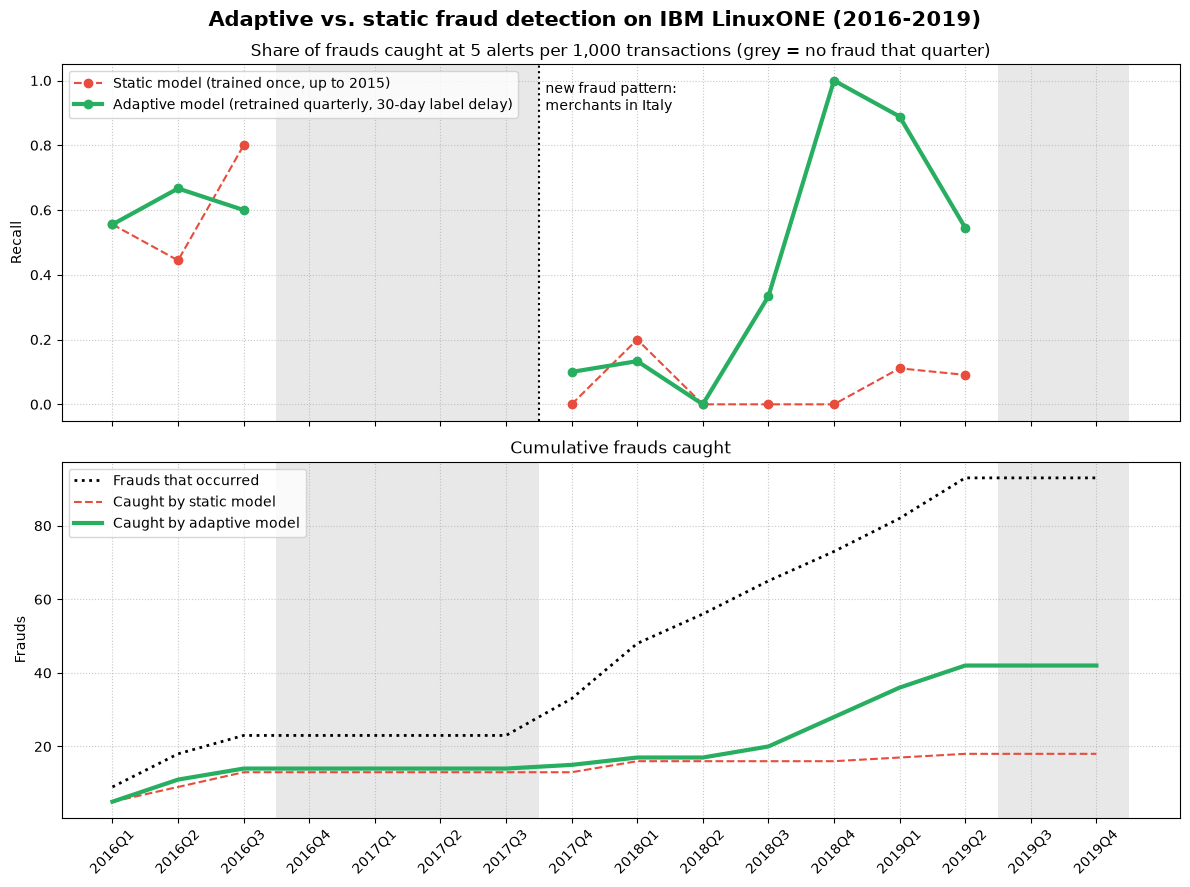

Chart saved to: docs/adaptive-chart.png


In [14]:
# === CELL: ADAPTIVE CHART ===
import matplotlib.pyplot as plt
import os

os.makedirs('docs', exist_ok=True)

x = np.arange(len(replay_df))
wave_start = int(replay_df.index[replay_df['Quarter'] == '2017Q4'][0])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
fig.suptitle('Adaptive vs. static fraud detection on IBM LinuxONE (2016-2019)', fontsize=15, fontweight='bold')

# Grey = quarters with no fraud at all (nothing to catch)
for i, n in enumerate(replay_df['Frauds']):
    if n == 0:
        for ax in (ax1, ax2):
            ax.axvspan(i - 0.5, i + 0.5, color='lightgrey', alpha=0.5, lw=0)

# Top: recall per quarter
ax1.plot(x, replay_df['Static_Recall'], 'o--', color='#e74c3c', label='Static model (trained once, up to 2015)')
ax1.plot(x, replay_df['Adaptive_Recall'], 'o-', color='#27ae60', linewidth=3,
         label='Adaptive model (retrained quarterly, 30-day label delay)')
ax1.axvline(wave_start - 0.5, color='black', linestyle=':')
ax1.text(wave_start - 0.4, 1.0, 'new fraud pattern:\nmerchants in Italy', fontsize=10, va='top')
ax1.set_title('Share of frauds caught at 5 alerts per 1,000 transactions (grey = no fraud that quarter)', fontsize=12)
ax1.set_ylabel('Recall')
ax1.set_ylim(-0.05, 1.05)
ax1.grid(True, linestyle=':', alpha=0.7)
ax1.legend(loc='upper left')

# Bottom: cumulative frauds caught
ax2.plot(x, replay_df['Frauds'].cumsum(), 'k:', linewidth=2, label='Frauds that occurred')
ax2.plot(x, replay_df['Static_Caught'].cumsum(), '--', color='#e74c3c', label='Caught by static model')
ax2.plot(x, replay_df['Adaptive_Caught'].cumsum(), '-', color='#27ae60', linewidth=3, label='Caught by adaptive model')
ax2.set_title('Cumulative frauds caught', fontsize=12)
ax2.set_ylabel('Frauds')
ax2.grid(True, linestyle=':', alpha=0.7)
ax2.legend(loc='upper left')
ax2.set_xticks(x)
ax2.set_xticklabels(replay_df['Quarter'], rotation=45)

plt.tight_layout()
chart_path = 'docs/adaptive-chart.png'
plt.savefig(chart_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Chart saved to: {chart_path}")

In [15]:
import json, joblib, os

os.makedirs('/home/ibm-user/shared/models', exist_ok=True)
M = '/home/ibm-user/shared/models/'

xgb_model.save_model(M + 'xgb.json')
model.save(M + 'tf_dense.keras')
lstm_model.save(M + 'lstm.keras')
joblib.dump(scaler, M + 'scaler.joblib')

json.dump({
    'feature_columns': FEATURE_COLUMNS, 
    'nn_features': NN_FEATURES,
    'blend_weights': [float(w) for w in best_w],
    'red_thr': float(red_thr), 
    'yellow_thr': float(yellow_thr),
    'tf_thr': float(tf_thr), 
    'lstm_thr': float(lstm_thr),
    'top_mccs': [int(m) for m in top_mccs], 
    'seq_len': SEQ_LEN,
}, open(M + 'config.json', 'w'), indent=2)

del X_all_seq   # frees ~600 MB
print("Successfully saved all production artifacts to:", M)

Successfully saved all production artifacts to: /home/ibm-user/shared/models/


In [16]:
# === CELL: LINUXONE PROOF (zDNN accelerator, ONNX export, latency) ===
import glob, os, time, importlib.metadata
import tf2onnx, onnx

os.makedirs('docs', exist_ok=True)
proof = {}

# 1. IBM Z AI accelerator: CPU facility, plugin, kernel library loaded in THIS process
with open('/proc/cpuinfo') as f:
    cpu_features = f.read()
proof['cpu_has_nnpa'] = ' nnpa' in cpu_features
proof['machine'] = platform.machine()
proof['zdnn_plugin_version'] = importlib.metadata.version('ibm-zdnn-plugin')
z_ops = glob.glob('/opt/venv/lib*/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so')
with open('/proc/self/maps') as f:
    loaded_libs = f.read()
proof['zdnn_kernels_file'] = z_ops[0] if z_ops else None
proof['zdnn_kernels_loaded_in_process'] = bool(z_ops) and z_ops[0] in loaded_libs
proof['tensorflow_version'] = tf.__version__

print("--- IBM Z AI accelerator (Telum NNPA) ---")
for k in ('machine', 'cpu_has_nnpa', 'zdnn_plugin_version', 'zdnn_kernels_file', 'zdnn_kernels_loaded_in_process', 'tensorflow_version'):
    print(f"  {k:32s}: {proof[k]}")

# 2. Inference speed of the neural models (direct model call; see the predict() note in the TF cell)
def time_calls(fn, repeats):
    fn()                                     # warm-up (graph build)
    t = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); t.append((time.perf_counter() - t0) * 1000)
    return float(np.median(t)), float(np.percentile(t, 95))

batch_tf = X_valid_scaled[:1000].astype('float32')
batch_lstm = X_valid_seq[:1000]
proof['tf_dense_batch1000_ms'] = time_calls(lambda: model(batch_tf, training=False).numpy(), 20)[0]
proof['lstm_batch1000_ms'] = time_calls(lambda: lstm_model(batch_lstm, training=False).numpy(), 20)[0]

# 3. Single-transaction latency of the full scoring path (XGBoost + TF + LSTM + blend)
booster = xgb_model.get_booster()
def score_one(i):
    d = xgb.DMatrix(X_valid.iloc[[i]])
    p_xgb = float(booster.predict(d)[0])
    booster.predict(d, pred_contribs=True)                       # reason codes
    p_tf = float(model(X_valid_scaled[i:i + 1].astype('float32'), training=False).numpy()[0, 0])
    p_lstm = float(lstm_model(X_valid_seq[i:i + 1], training=False).numpy()[0, 0])
    return best_w[0] * p_xgb + best_w[1] * p_lstm + best_w[2] * p_tf
score_one(0)
lat = []
for i in range(1, 501):
    t0 = time.perf_counter(); score_one(i); lat.append((time.perf_counter() - t0) * 1000)
proof['single_tx_latency_ms_median'] = float(np.median(lat))
proof['single_tx_latency_ms_p95'] = float(np.percentile(lat, 95))

print("\n--- Inference speed on LinuxONE ---")
print(f"  TF dense, 1,000 transactions : {proof['tf_dense_batch1000_ms']:.1f} ms")
print(f"  LSTM, 1,000 sequences        : {proof['lstm_batch1000_ms']:.1f} ms")
print(f"  One transaction, all 3 models + reason codes: median {proof['single_tx_latency_ms_median']:.1f} ms, "
      f"p95 {proof['single_tx_latency_ms_p95']:.1f} ms")

# 4. ONNX export of both neural models (portable format: train anywhere, infer on IBM Z)
def export_onnx(m, shape, path):
    spec = [tf.TensorSpec(shape, tf.float32, name='input')]
    @tf.function(input_signature=spec)
    @tf.autograph.experimental.do_not_convert
    def fn(x):
        return m(x, training=False)
    onnx_model, _ = tf2onnx.convert.from_function(fn, input_signature=spec, opset=13)
    onnx.save_model(onnx_model, path)
    return os.path.getsize(path)

MODEL_DIR = '/home/ibm-user/shared/models/'
proof['onnx_tf_dense_bytes'] = export_onnx(model, [None, X_valid_scaled.shape[1]], MODEL_DIR + 'tf_dense.onnx')
proof['onnx_lstm_bytes'] = export_onnx(lstm_model, [None, SEQ_LEN, X_valid_seq.shape[2]], MODEL_DIR + 'lstm.onnx')
print("\n--- ONNX export ---")
print(f"  {MODEL_DIR}tf_dense.onnx ({proof['onnx_tf_dense_bytes'] / 1024:.0f} KB)")
print(f"  {MODEL_DIR}lstm.onnx ({proof['onnx_lstm_bytes'] / 1024:.0f} KB)")

with open('docs/linuxone_proof.json', 'w') as f:
    json.dump(proof, f, indent=2)
print("\nSaved docs/linuxone_proof.json (numbers for the README)")

--- IBM Z AI accelerator (Telum NNPA) ---
  machine                         : s390x
  cpu_has_nnpa                    : True
  zdnn_plugin_version             : 2.3.0
  zdnn_kernels_file               : /opt/venv/lib/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so
  zdnn_kernels_loaded_in_process  : True
  tensorflow_version              : 2.18.1



--- Inference speed on LinuxONE ---
  TF dense, 1,000 transactions : 2.0 ms
  LSTM, 1,000 sequences        : 31.4 ms
  One transaction, all 3 models + reason codes: median 24.6 ms, p95 26.0 ms


I0000 00:00:1792261159.485569    6982 devices.cc:76] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0 (Note: TensorFlow was not compiled with CUDA or ROCm support)
I0000 00:00:1792261159.485720    6982 single_machine.cc:361] Starting new session
I0000 00:00:1792261159.539397    6982 devices.cc:76] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0 (Note: TensorFlow was not compiled with CUDA or ROCm support)
I0000 00:00:1792261159.539475    6982 single_machine.cc:361] Starting new session


I0000 00:00:1792261159.718785    6982 devices.cc:76] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0 (Note: TensorFlow was not compiled with CUDA or ROCm support)
I0000 00:00:1792261159.718920    6982 single_machine.cc:361] Starting new session


I0000 00:00:1792261160.131339    6982 devices.cc:76] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0 (Note: TensorFlow was not compiled with CUDA or ROCm support)
I0000 00:00:1792261160.131503    6982 single_machine.cc:361] Starting new session
I0000 00:00:1792261160.253101    6982 mlir_graph_optimization_pass.cc:401] MLIR V1 optimization pass is not enabled



--- ONNX export ---
  /home/ibm-user/shared/models/tf_dense.onnx (24 KB)
  /home/ibm-user/shared/models/lstm.onnx (63 KB)

Saved docs/linuxone_proof.json (numbers for the README)


In [17]:
# === CELL: FINAL TEST EVALUATION (2018-2019, run once, frozen validation settings) ===
# Weights (best_w) and thresholds (red_thr, yellow_thr) were chosen on validation; nothing is tuned here.
test_mask = (df['split'] == 'test').values
test_df = df[test_mask]
y_test = test_df['is_fraud'].values

xgb_test = xgb_model.predict_proba(test_df[FEATURE_COLUMNS])[:, 1]
X_test_scaled = np.clip(scaler.transform(test_df[NN_FEATURES]), -10, 10).astype('float32')
tf_test = model(X_test_scaled, training=False).numpy().ravel()
X_test_seq = create_sequences_all(np.clip(scaler.transform(df[NN_FEATURES]), -10, 10))[test_mask]
lstm_test = np.concatenate([lstm_model(X_test_seq[i:i + 4096], training=False).numpy().ravel()
                            for i in range(0, len(X_test_seq), 4096)])
blend_test = best_w[0] * xgb_test + best_w[1] * lstm_test + best_w[2] * tf_test

print(f"Test set: {len(y_test)} transactions, {int(y_test.sum())} frauds (2018-2019)\n")
print("Blended model, threshold frozen from validation (5 alerts per 1,000 there):")
test_blend_metrics = report(y_test, blend_test, threshold=yellow_thr)
print("\nXGBoost alone, threshold frozen from validation:")
test_xgb_metrics = report(y_test, xgb_test, threshold=threshold_for_budget(xgb_probs, alerts_per_1000=5))

test_tier = np.select([blend_test >= red_thr, blend_test >= yellow_thr], ['RED', 'YELLOW'], default='CLEAR')
print("\nRouting on test with the validation thresholds:")
print(pd.DataFrame({'Action_Tier': test_tier, 'is_fraud': y_test})
      .groupby('Action_Tier')['is_fraud'].agg(transactions='size', frauds='sum'))
print("\nNote: almost all 2018-2019 fraud belongs to the new pattern that started in late 2017 "
      "(merchants in Italy). A model frozen on earlier data misses most of it; the stream replay above "
      "shows how quarterly retraining recovers it.")
del X_test_seq

Test set: 33543 transactions, 60 frauds (2018-2019)

Blended model, threshold frozen from validation (5 alerts per 1,000 there):
--- Evaluation at fixed threshold ---
  threshold       : 0.252673
  precision       : 0.054264
  recall          : 0.116667
  pr_auc          : 0.021552
  fpr             : 0.003644
  alerts_per_1000 : 3.845810

XGBoost alone, threshold frozen from validation:
--- Evaluation at fixed threshold ---
  threshold       : 0.007412
  precision       : 0.040230
  recall          : 0.116667
  pr_auc          : 0.011497
  fpr             : 0.004988
  alerts_per_1000 : 5.187371

Routing on test with the validation thresholds:
             transactions  frauds
Action_Tier                      
CLEAR               33414      53
RED                    29       1
YELLOW                100       6

Note: almost all 2018-2019 fraud belongs to the new pattern that started in late 2017 (merchants in Italy). A model frozen on earlier data misses most of it; the stream replay a